Comparison libraries are not project dependencies; run this notebook with:

```bash
uv run --with biotite --with prody --with rdkit --with biopython \
    jupyter nbconvert --to notebook --execute --inplace benchmark.ipynb
```

In [1]:
import os
import time

DATA_DIR = "./tests/test_data"
PDB_FILES = sorted(os.listdir(DATA_DIR))
N_REPEATS = 5

results = {}


def bench(name, parse_fn):
    """Parse every test file N_REPEATS times and record the total wall time in seconds."""
    start = time.perf_counter()
    for pdb in PDB_FILES * N_REPEATS:
        parse_fn(f"{DATA_DIR}/{pdb}")
    results[name] = time.perf_counter() - start
    print(f"{name}: {results[name]:.2f} s")

### CPDB

In [2]:
from cpdb import parse

In [3]:
bench("CPDB (dict)", lambda f: parse(f, df=False))

CPDB (dict): 0.74 s


In [4]:
bench("CPDB", lambda f: parse(f, df=True))

CPDB: 1.04 s


### BioPandas

In [5]:
from biopandas.pdb import PandasPdb

ppdb = PandasPdb()

In [6]:
bench("BioPandas", ppdb.read_pdb)

BioPandas: 25.28 s


### Prody

In [7]:
from prody import confProDy, parsePDB

confProDy(verbosity="none")

In [8]:
bench("ProDy", parsePDB)

ProDy: 3.44 s


### BioTite

In [9]:
from biotite.structure.io.pdb import PDBFile

In [10]:
bench("Biotite", lambda f: PDBFile.read(f).get_structure())

Biotite: 6.15 s


### BioPython

In [11]:
import warnings

warnings.filterwarnings("ignore")

from Bio.PDB import PDBParser

bpparser = PDBParser()

In [12]:
bench("Biopython", lambda f: bpparser.get_structure(None, f))

Biopython: 26.18 s


### RDKit

In [13]:
from rdkit import Chem

In [14]:
bench("RDKit", Chem.MolFromPDBFile)

RDKit: 4.51 s


### Plot

Writes the light and dark README charts to `docs/`.

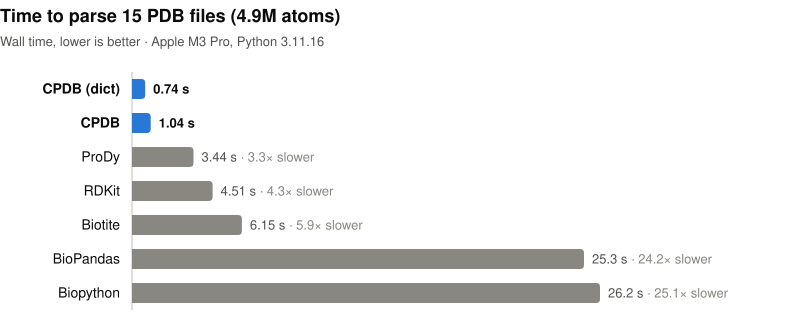

In [15]:
import platform
import subprocess
from html import escape

from cpdb.parser import parse_pdb_file

n_atoms = sum(len(parse_pdb_file(f"{DATA_DIR}/{pdb}")["x_coord"]) for pdb in PDB_FILES) * N_REPEATS
cpu = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip() or platform.processor()

THEMES = {  # ink and bar colours per GitHub theme; the background stays transparent
    "light": dict(primary="#0b0b0b", secondary="#52514e", muted="#898781", baseline="#c3c2b7", accent="#2a78d6", neutral="#898781"),
    "dark": dict(primary="#f0efec", secondary="#c3c2b7", muted="#898781", baseline="#3d444d", accent="#3987e5", neutral="#76756f"),
}


def bar_chart_svg(results, theme):
    c = THEMES[theme]
    rows = sorted(results.items(), key=lambda kv: kv[1])
    cpdb_secs = results["CPDB"]
    width, left, right, top, row_h, bar_h = 800, 132, 200, 72, 34, 20
    plot_w = width - left - right
    height = top + row_h * len(rows) + 8
    x = lambda v: left + plot_w * v / rows[-1][1]
    fmt = lambda v: f"{v:.2f}" if v < 10 else f"{v:.1f}"

    out = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" '
        f'font-family="system-ui, -apple-system, \'Segoe UI\', Helvetica, Arial, sans-serif">',
        f"<title>PDB parsing time by library (lower is better)</title>",
        "<desc>" + escape("; ".join(f"{k}: {v:.2f} s" for k, v in rows)) + "</desc>",
        f'<text x="0" y="22" font-size="18" font-weight="600" fill="{c["primary"]}">Time to parse {len(PDB_FILES) * N_REPEATS} PDB files ({n_atoms / 1e6:.1f}M atoms)</text>',
        f'<text x="0" y="46" font-size="13" fill="{c["secondary"]}">Wall time, lower is better · {escape(cpu)}, Python {platform.python_version()}</text>',
    ]
    # Every bar carries its value, so there's no value axis: just the baseline
    out.append(f'<line x1="{left}" x2="{left}" y1="{top}" y2="{top + row_h * len(rows)}" stroke="{c["baseline"]}" stroke-width="1"/>')
    for i, (name, secs) in enumerate(rows):
        is_cpdb = name.startswith("CPDB")
        cy = top + row_h * i + row_h / 2
        y0, x1, r = cy - bar_h / 2, max(x(secs), left + 4), 4  # square at the baseline, 4px rounded data-end
        out.append(f'<path d="M{left},{y0} H{x1 - r:.1f} Q{x1:.1f},{y0} {x1:.1f},{y0 + r} V{y0 + bar_h - r} Q{x1:.1f},{y0 + bar_h} {x1 - r:.1f},{y0 + bar_h} H{left} Z" '
                   f'fill="{c["accent"] if is_cpdb else c["neutral"]}"/>')
        weight = ' font-weight="600"' if is_cpdb else ""
        out.append(f'<text x="{left - 12}" y="{cy + 4.5}" font-size="14"{weight} fill="{c["primary"]}" text-anchor="end">{escape(name)}</text>')
        note = f' <tspan fill="{c["muted"]}">· {secs / cpdb_secs:.1f}× slower</tspan>' if not is_cpdb else ""
        out.append(f'<text x="{x1 + 8:.1f}" y="{cy + 4.5}" font-size="13"{weight} fill="{c["primary"] if is_cpdb else c["secondary"]}" '
                   f'>{fmt(secs)} s{note}</text>')
    out.append("</svg>")
    return "\n".join(out) + "\n"


for theme in THEMES:
    with open(f"docs/benchmark-{theme}.svg", "w") as f:
        f.write(bar_chart_svg(results, theme))

from IPython.display import SVG, display
display(SVG("docs/benchmark-light.svg"))